# Predicting 30-Day Hospital Readmission Among Patients With Diabetes
## Deliverable 2: Exploratory Data Analysis and Preprocessing

**Team:** Diego Alejandro Salazar Sarmiento, Brandan Kwok
**Dataset:** Diabetes 130-US Hospitals for Years 1999-2008 (UCI Machine Learning Repository)

This notebook runs top to bottom without edits. It expects `diabetic_data.csv` and `IDS_mapping.csv`
in a `data/` folder next to the notebook or one level up (the layout used in the submitted zip).
Every figure is generated by the code and also written to `figures/`.

**Contents**
1. Load data and overview
2. Data quality checks (missingness, duplicates, invalid values)
3. Cohort and binary target
4. Hidden missing codes and uninformative columns
5. Patient-grouped train/test split
6. Exploratory data analysis
7. Preprocessing (missing values, outliers, encoding, scaling)
8. Feature selection
9. Dimensionality reduction
10. Class imbalance and data augmentation
11. Outputs and summary

In [1]:
# Imports and settings
import csv
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
TEST_SIZE = 0.20
np.random.seed(RANDOM_STATE)

# Read diabetic_data.csv
_candidates = [Path("data"), Path("../data"), Path("."), Path(".."),
               Path("/mnt/user-data/uploads")]
DATA_DIR = next((p for p in _candidates if (p / "diabetic_data.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find diabetic_data.csv. Put it in ./data or set DATA_DIR manually."
    )

PROJECT_ROOT = DATA_DIR.parent if DATA_DIR.name == "data" else DATA_DIR
FIG_DIR = Path("figures")
PROC_DIR = Path("processed")
FIG_DIR.mkdir(exist_ok=True)
PROC_DIR.mkdir(exist_ok=True)

# Show plots inline in notebooks/Colab; only save them when run as a plain script.
SHOW_PLOTS = "get_ipython" in globals()


def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

# 1. Load data and overview

In [2]:
# Missing values are coded as "?" in this dataset, so convert only those to NaN on load.
# keep_default_na=False matters: otherwise pandas also turns the string "None" into NaN,
# but in A1Cresult / max_glu_serum "None" means "test not performed" (real information).
df_raw = pd.read_csv(DATA_DIR / "diabetic_data.csv", na_values=["?"], keep_default_na=False,
                     low_memory=False)

print("Shape:", df_raw.shape)
print("\nColumn types:")
print(df_raw.dtypes.value_counts())
print("\nFirst rows:")
print(df_raw.head())

print("\nUnique encounters:", df_raw["encounter_id"].nunique())
print("Unique patients  :", df_raw["patient_nbr"].nunique())

num_cols_all = df_raw.select_dtypes(include="number").columns.tolist()
cat_cols_all = df_raw.select_dtypes(exclude="number").columns.tolist()
print(f"\n{len(num_cols_all)} numeric columns, {len(cat_cols_all)} non-numeric columns")

print("\nOriginal 3-class target distribution:")
vc = df_raw["readmitted"].value_counts()
print(pd.DataFrame({"count": vc, "percent": (vc / len(df_raw) * 100).round(2)}))

print("\nNumeric summary:")
print(df_raw.select_dtypes(include="number").drop(columns=["encounter_id", "patient_nbr"]).describe().T)

Shape: (101766, 50)

Column types:
str      37
int64    13
Name: count, dtype: int64

First rows:
   encounter_id  patient_nbr             race  gender      age weight  admission_type_id  discharge_disposition_id  admission_source_id  time_in_hospital  \
0       2278392      8222157        Caucasian  Female   [0-10)    NaN                  6                        25                    1                 1   
1        149190     55629189        Caucasian  Female  [10-20)    NaN                  1                         1                    7                 3   
2         64410     86047875  AfricanAmerican  Female  [20-30)    NaN                  1                         1                    7                 2   
3        500364     82442376        Caucasian    Male  [30-40)    NaN                  1                         1                    7                 2   
4         16680     42519267        Caucasian    Male  [40-50)    NaN                  1                         1   

**Notes**
- 101,766 encounters and 50 columns. Each row is one hospital stay, not one person: there are only
  71,518 distinct `patient_nbr` values, so some patients appear many times.
- 13 columns are stored as integers, but three of them (`admission_type_id`, `discharge_disposition_id`,
  `admission_source_id`) are nominal codes described in `IDS_mapping.csv`, so they are treated as
  categorical later. `encounter_id` and `patient_nbr` are identifiers, not predictors.
- The remaining true numeric features are eight counts (days in hospital, lab tests, procedures,
  medications, prior outpatient/emergency/inpatient visits, number of diagnoses).
- The 3-class target is unbalanced: 53.9% `NO`, 34.9% `>30`, 11.2% `<30`.

# 2. Data quality checks

In [3]:
# Missingness ("?" values) before any cleaning
miss_before = df_raw.isna().mean()
miss_tbl = pd.DataFrame({"n_missing": df_raw.isna().sum(), "pct_missing": (miss_before * 100).round(2)})
print("Columns with '?' values:")
print(miss_tbl[miss_tbl["n_missing"] > 0].sort_values("pct_missing", ascending=False))

# Duplicates
id_cols = ["encounter_id", "patient_nbr"]
print("\nFully duplicated rows            :", df_raw.duplicated().sum())
print("Duplicated encounter_id          :", df_raw["encounter_id"].duplicated().sum())
print("Duplicated rows ignoring the IDs :", df_raw.drop(columns=id_cols).duplicated().sum())
repeat = df_raw["patient_nbr"].duplicated(keep=False)
print(f"Encounters from repeat patients  : {repeat.sum():,} ({repeat.mean() * 100:.1f}%)")

# Placeholder / invalid values that are not coded as "?"
print("\ngender values:", df_raw["gender"].value_counts().to_dict())
print("A1Cresult values:", df_raw["A1Cresult"].value_counts().to_dict())
print("max_glu_serum values:", df_raw["max_glu_serum"].value_counts().to_dict())

# Range check of the count features (negative or impossible values would be data errors)
COUNT_COLS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
              "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
print("\nRange of count features:")
print(df_raw[COUNT_COLS].agg(["min", "max"]).T)

# Is missingness related to the outcome? (if yes, "missing" itself carries information)
y_raw = df_raw["readmitted"].eq("<30")
miss_vs_target = pd.DataFrame(
    {c: {"rate_if_missing %": y_raw[df_raw[c].isna()].mean() * 100,
         "rate_if_present %": y_raw[df_raw[c].notna()].mean() * 100}
     for c in miss_tbl.index[miss_tbl["n_missing"] > 100]}
).T.round(2)
print("\n<30-day readmission rate when the value is missing vs present:")
print(miss_vs_target)

# diag_2 / diag_3 missing: is it simply "no secondary diagnosis"?
print("\nMedian number_diagnoses when diag_3 is missing:",
      df_raw.loc[df_raw["diag_3"].isna(), "number_diagnoses"].median(),
      "| overall:", df_raw["number_diagnoses"].median())

Columns with '?' values:
                   n_missing  pct_missing
weight                 98569        96.86
medical_specialty      49949        49.08
payer_code             40256        39.56
race                    2273         2.23
diag_3                  1423         1.40
diag_2                   358         0.35
diag_1                    21         0.02



Fully duplicated rows            : 0
Duplicated encounter_id          : 0


Duplicated rows ignoring the IDs : 0
Encounters from repeat patients  : 47,021 (46.2%)

gender values: {'Female': 54708, 'Male': 47055, 'Unknown/Invalid': 3}
A1Cresult values: {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}
max_glu_serum values: {'None': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}

Range of count features:
                    min  max
time_in_hospital      1   14
num_lab_procedures    1  132
num_procedures        0    6
num_medications       1   81
number_outpatient     0   42
number_emergency      0   76
number_inpatient      0   21
number_diagnoses      1   16

<30-day readmission rate when the value is missing vs present:
                   rate_if_missing %  rate_if_present %
race                            8.27              11.23
weight                         11.16              11.17
payer_code                     11.49              10.94
medical_specialty              11.57              10.76
diag_2                          8.10              11.17
dia

**Notes**
- **Missingness.** Seven columns contain `?`. `weight` is almost empty (96.9%) and will be dropped.
  `medical_specialty` (49.1%) and `payer_code` (39.6%) are missing for a large share of encounters,
  while `race` (2.2%) and the diagnosis codes (at most 1.4%) are only slightly incomplete.
- **Missingness is not random.** Encounters with missing `race` have a lower `<30` rate (8.3% vs 11.2%),
  and a missing `diag_3` almost always belongs to a stay with only one or two diagnoses recorded
  (structural missingness). Filling these with the most frequent value would hide that signal, so
  missing categories are kept as an explicit `Missing` level in Section 7.
- **Duplicates.** There are no duplicated rows and no duplicated `encounter_id`, even after ignoring the
  identifiers. However, 46% of encounters belong to patients with more than one stay. These are not
  duplicates to delete; they are a grouping structure, which is why the split in Section 5 is by patient.
- **Hidden missing values.** Three encounters have `gender = Unknown/Invalid`, and several admission/discharge
  IDs mean "NULL / Not Available / Not Mapped" (handled in Section 4). In `A1Cresult` and `max_glu_serum`,
  `None` means the test was not done, which is real information and not a missing value.
- **Ranges.** All count features are non-negative and within plausible limits (stay of 1-14 days,
  1-16 diagnoses), so no values are rejected as data-entry errors.

# 3. Cohort and binary target

In [4]:
df = df_raw.copy()

# Binary target: 1 = readmitted within 30 days ("<30"), 0 = ">30" or "NO"
df["target"] = (df["readmitted"] == "<30").astype(int)

# Cohort flow table (record every exclusion for the report)
flow = [("Original dataset", len(df))]

# Exclude discharges to death / hospice: these patients cannot be readmitted.
# IDs: 11 Expired, 13 Hospice/home, 14 Hospice/medical facility, 19/20/21 Expired (Medicaid only, hospice)
EXCLUDE_DISCHARGE = [11, 13, 14, 19, 20, 21]
mask_death_hospice = df["discharge_disposition_id"].isin(EXCLUDE_DISCHARGE)
print(f"Removing {mask_death_hospice.sum()} encounters discharged to death/hospice")
df = df[~mask_death_hospice]
flow.append(("After removing death/hospice discharges", len(df)))

# Exclude invalid gender rows
mask_gender = df["gender"] == "Unknown/Invalid"
print(f"Removing {mask_gender.sum()} encounters with invalid gender")
df = df[~mask_gender]
flow.append(("After removing invalid gender", len(df)))

df = df.reset_index(drop=True)

flow_df = pd.DataFrame(flow, columns=["step", "n_encounters"])
flow_df["removed"] = -flow_df["n_encounters"].diff().fillna(0).astype(int)
print("\nCohort flow:")
print(flow_df.to_string(index=False))
print(f"\nPositive rate (<30 days) in cohort: {df['target'].mean() * 100:.2f}%")
print(f"Unique patients in cohort: {df['patient_nbr'].nunique()}")

# The 3-class label has now served its purpose; drop it so it cannot leak into features.
# encounter_id is just an identifier and is not a predictor.
df = df.drop(columns=["readmitted", "encounter_id"])

Removing 2423 encounters discharged to death/hospice
Removing 3 encounters with invalid gender



Cohort flow:
                                   step  n_encounters  removed
                       Original dataset        101766        0
After removing death/hospice discharges         99343     2423
          After removing invalid gender         99340        3

Positive rate (<30 days) in cohort: 11.39%
Unique patients in cohort: 69987


**Notes**
- Following Strack et al. (2014), encounters that ended in death or hospice (2,423) are removed because
  these patients cannot be readmitted; keeping them would add negatives that are impossible to predict.
  The three rows with invalid gender are also removed.
- The analysis cohort has 99,340 encounters from 69,987 patients and an 11.39% positive rate.
  The 3-class `readmitted` column is dropped right after building the target so it cannot leak.

# 4. Hidden missing codes and uninformative columns

In [5]:
# IDS_mapping.csv contains 3 small tables separated by blank rows.
# Return {id_column_name: {id: description}}
def parse_ids_mapping(path):
    tables, current = {}, None
    with open(path, newline="") as f:
        for row in csv.reader(f):
            if not row or all(c.strip() == "" for c in row):
                current = None
                continue
            if len(row) > 1 and row[1].strip() == "description":
                current = row[0].strip()
                tables[current] = {}
                continue
            if current is not None:
                tables[current][int(row[0])] = row[1].strip()
    return tables


id_maps = parse_ids_mapping(DATA_DIR / "IDS_mapping.csv")
print("Mapping tables found:", {k: len(v) for k, v in id_maps.items()})

# Some IDs mean "we don't know" -> treat as missing
NULL_LIKE = {"NULL", "Not Available", "Not Mapped", "Unknown/Invalid"}
ID_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

for col in ID_COLS:
    null_ids = [i for i, d in id_maps[col].items() if d in NULL_LIKE]
    n_null = df[col].isin(null_ids).sum()
    print(f"{col}: null-like ids {null_ids} -> {n_null} rows ({n_null / len(df) * 100:.1f}%)")
    df[col] = df[col].where(~df[col].isin(null_ids), np.nan)
    # Store IDs as strings so they get one-hot encoded later
    df[col] = df[col].map(lambda v: np.nan if pd.isna(v) else str(int(v)))

# "None" in these two lab-result columns means "test not performed". Rename it so that
# pandas never mistakes it for a missing value when the saved CSVs are read back in later.
for col in ["A1Cresult", "max_glu_serum"]:
    df[col] = df[col].replace("None", "NotTested")
    print(f"{col} values:", df[col].value_counts().to_dict())

# Drop Weight since most of it is missing
print(f"\nDropping 'weight' ({miss_before['weight'] * 100:.1f}% missing)")
df = df.drop(columns=["weight"])

# Drop constant columns (single value = no information)
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Dropping constant columns:", const_cols)
df = df.drop(columns=const_cols)

# Report near-constant drug columns
drug_cols = [c for c in df.columns if df[c].isin(["No", "Steady", "Up", "Down"]).all()]
near_const = [c for c in drug_cols if (df[c] == "No").mean() > 0.99]
print(f"\n{len(drug_cols)} medication columns; {len(near_const)} have 'No' in >99% of rows:")
print(near_const)

# Remaining missingness after cleaning (cohort only)
miss_after = df.isna().mean()
print("\nMissing values remaining (percent):")
print((miss_after[miss_after > 0] * 100).round(2).sort_values(ascending=False))
print("\nNOTE: imputation is deliberately not done here. It must be fit on the training set")

Mapping tables found: {'admission_type_id': 8, 'discharge_disposition_id': 30, 'admission_source_id': 25}
admission_type_id: null-like ids [5, 6, 8] -> 10144 rows (10.2%)
discharge_disposition_id: null-like ids [18, 25, 26] -> 4680 rows (4.7%)


admission_source_id: null-like ids [9, 15, 17, 20, 21] -> 6854 rows (6.9%)
A1Cresult values: {'NotTested': 82506, '>8': 8137, 'Norm': 4922, '>7': 3775}
max_glu_serum values: {'NotTested': 94188, 'Norm': 2545, '>200': 1419, '>300': 1188}

Dropping 'weight' (96.9% missing)


Dropping constant columns: ['examide', 'citoglipton']



21 medication columns; 13 have 'No' in >99% of rows:
['nateglinide', 'chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']



Missing values remaining (percent):
medical_specialty           48.94
payer_code                  39.66
admission_type_id           10.21
admission_source_id          6.90
discharge_disposition_id     4.71
race                         2.25
diag_3                       1.43
diag_2                       0.36
diag_1                       0.02
dtype: float64

NOTE: imputation is deliberately not done here. It must be fit on the training set


**Notes**
- The ID mapping file reveals hidden missing values: 10.2% of `admission_type_id`, 6.9% of
  `admission_source_id` and 4.7% of `discharge_disposition_id` are "NULL", "Not Available" or "Not Mapped".
  They are converted to NaN so they are treated the same way as `?`.
- `weight` (96.9% missing) is dropped, and `examide` and `citoglipton` are dropped because they take a single
  value. Thirteen other medication columns are almost constant (>99% `No`); they are kept for now and left
  to the feature-selection step in Section 8, which removes them using a rule fit on the training data only.
- No imputation is done before the split, so the test set never influences any fitted statistic.

# 5. Patient-grouped train/test split

In [6]:
# Many patients have several encounters. Splitting by patient_nbr stops the same patient
# appearing in both train and test (which would leak information and inflate scores).
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(df, df["target"], groups=df["patient_nbr"]))

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Sanity checks
overlap = set(train_df["patient_nbr"]) & set(test_df["patient_nbr"])
assert len(overlap) == 0, "Patient leakage between train and test!"
print("Patients in both train and test:", len(overlap), "(good)")

summary = pd.DataFrame(
    {
        "encounters": [len(train_df), len(test_df)],
        "patients": [train_df["patient_nbr"].nunique(), test_df["patient_nbr"].nunique()],
        "positives (<30)": [train_df["target"].sum(), test_df["target"].sum()],
        "positive rate %": [
            round(train_df["target"].mean() * 100, 2),
            round(test_df["target"].mean() * 100, 2),
        ],
    },
    index=["train", "test"],
)
print("\n", summary)
print(f"Actual test fraction: {len(test_df) / len(df):.3f}")

train_df.to_csv(PROC_DIR / "train_clean.csv", index=False)
test_df.to_csv(PROC_DIR / "test_clean.csv", index=False)
print(f"\nSaved {PROC_DIR / 'train_clean.csv'} and {PROC_DIR / 'test_clean.csv'}")

Patients in both train and test: 0 (good)

        encounters  patients  positives (<30)  positive rate %
train       79567     55989             9070            11.40
test        19773     13998             2244            11.35
Actual test fraction: 0.199



Saved processed\train_clean.csv and processed\test_clean.csv


**Notes**
- 80/20 split by `patient_nbr`: no patient appears in both sets, and the positive rate is almost identical
  (11.40% train, 11.35% test), so stratification is not needed on top of grouping.
- From here on, all EDA plots use **only the training split**. The test set is kept untouched so that
  nothing we look at or fit leaks into the final evaluation.

# 6. Exploratory data analysis (training split)

In [7]:
# EDA setup (copy so the label column does not end up in train_df)
eda_df = train_df.copy()
eda_df["target_label"] = eda_df["target"].map({0: "Not <30d", 1: "Readmitted <30d"})

NUMERIC_FEATURES = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
]

## 6.1 Target distribution and missingness

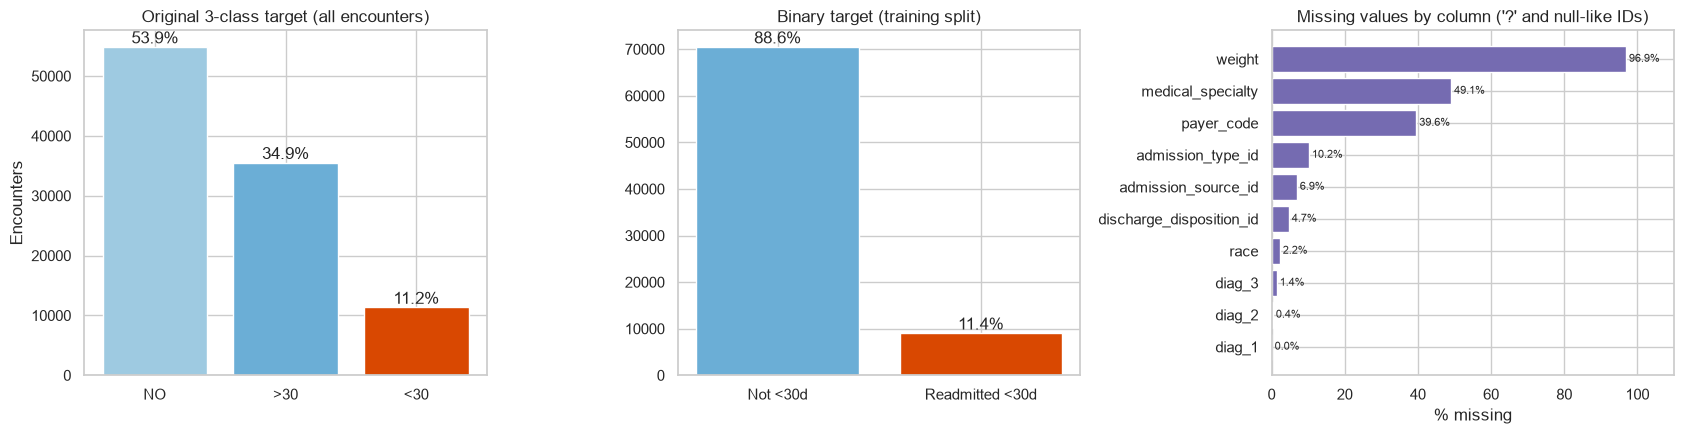

In [8]:
# Target distribution and missingness
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

orig = df_raw["readmitted"].value_counts().reindex(["NO", ">30", "<30"])
axes[0].bar(orig.index, orig.values, color=["#9ecae1", "#6baed6", "#d94801"])
for i, v in enumerate(orig.values):
    axes[0].text(i, v, f"{v / orig.sum() * 100:.1f}%", ha="center", va="bottom")
axes[0].set_title("Original 3-class target (all encounters)")
axes[0].set_ylabel("Encounters")

binary = eda_df["target_label"].value_counts().reindex(["Not <30d", "Readmitted <30d"])
axes[1].bar(binary.index, binary.values, color=["#6baed6", "#d94801"])
for i, v in enumerate(binary.values):
    axes[1].text(i, v, f"{v / binary.sum() * 100:.1f}%", ha="center", va="bottom")
axes[1].set_title("Binary target (training split)")

# Missingness: '?' values from raw data, plus hidden nulls for the 3 ID columns
miss_plot = miss_before.copy()
for c in ID_COLS:
    miss_plot[c] = miss_after[c]
miss_plot = (miss_plot[miss_plot > 0] * 100).sort_values()
axes[2].barh(miss_plot.index, miss_plot.values, color="#756bb1")
for y, v in enumerate(miss_plot.values):
    axes[2].text(v, y, f" {v:.1f}%", va="center", fontsize=8)
axes[2].set_xlim(0, 110)
axes[2].set_xlabel("% missing")
axes[2].set_title("Missing values by column ('?' and null-like IDs)")

save_show(fig, "01_target_and_missingness")

**Notes**
- After binarising, only 11.4% of training encounters are positive (about 7.8 negatives per positive).
  A model that always predicts "not readmitted" would be 88.6% accurate, so accuracy is not a useful
  metric here; this supports PR-AUC as the primary metric and imbalance handling in Section 10.
- Missingness is concentrated in a few administrative columns (`weight`, `medical_specialty`, `payer_code`).

## 6.2 Distributions of numeric features

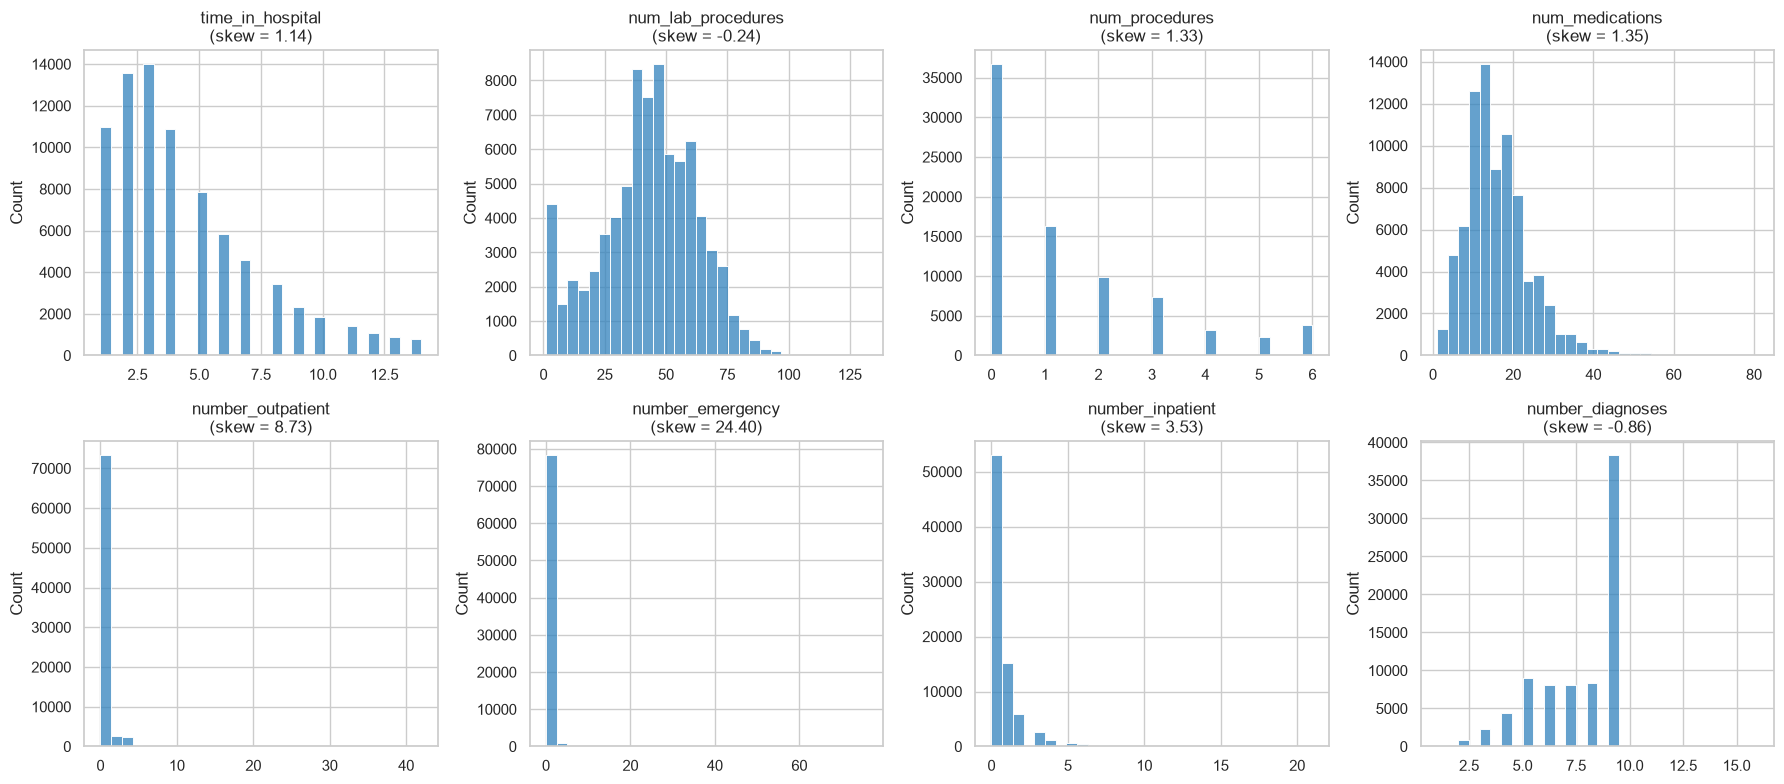

Skewness of numeric features:
number_emergency      24.40
number_outpatient      8.73
number_inpatient       3.53
num_medications        1.35
num_procedures         1.33
time_in_hospital       1.14
num_lab_procedures    -0.24
number_diagnoses      -0.86
dtype: float64


In [9]:
# Distributions of numeric features
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(eda_df[col], bins=30, ax=ax, color="#3182bd")
    ax.set_title(f"{col}\n(skew = {eda_df[col].skew():.2f})")
    ax.set_xlabel("")
save_show(fig, "02_numeric_histograms")

print("Skewness of numeric features:")
print(eda_df[NUMERIC_FEATURES].skew().round(2).sort_values(ascending=False))

**Notes**
- The three prior-visit counts are extremely right-skewed (`number_emergency` skew 24.4,
  `number_outpatient` 8.7, `number_inpatient` 3.5): most patients have zero prior visits and a few have many.
- `time_in_hospital`, `num_medications` and `num_procedures` are moderately right-skewed;
  `num_lab_procedures` is close to symmetric, and `number_diagnoses` is left-skewed with a large spike at 9
  (very few encounters record more than 9 diagnoses).
- The skew motivates a log transform and robust handling of large values before scaling (Section 7).

## 6.3 Box plots by target and outlier counts

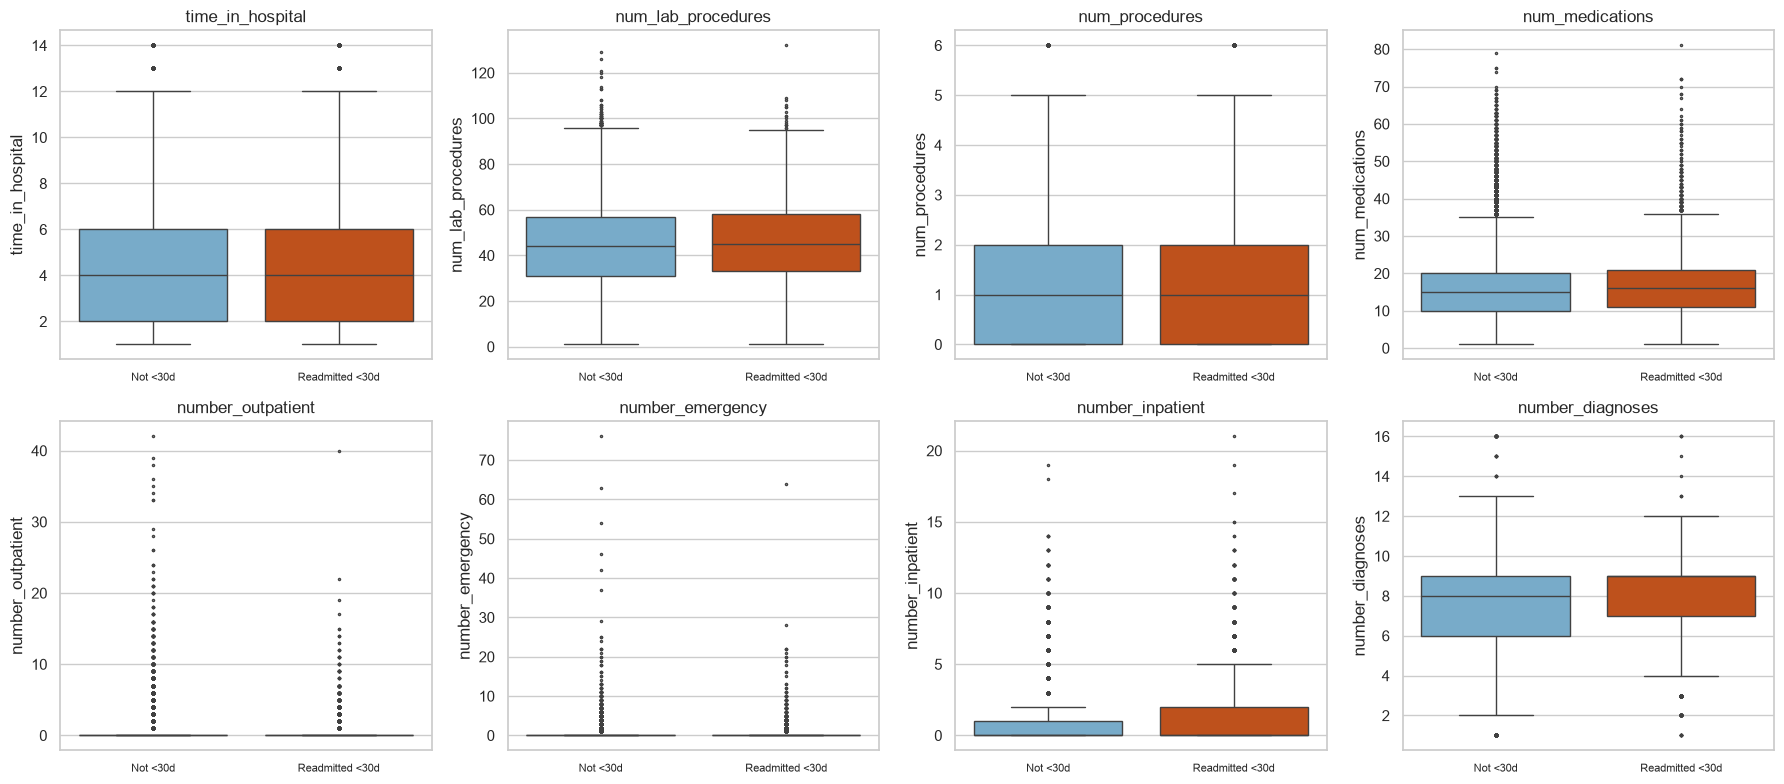


IQR outlier summary:
           feature  lower_fence  upper_fence  n_outliers  pct_outliers  max
  time_in_hospital         -4.0         12.0        1697          2.13   14
num_lab_procedures         -8.0         96.0          87          0.11  132
    num_procedures         -3.0          5.0        3841          4.83    6
   num_medications         -5.0         35.0        1990          2.50   81
 number_outpatient          0.0          0.0       13039         16.39   42
  number_emergency          0.0          0.0        8923         11.21   76
  number_inpatient         -1.5          2.5        5520          6.94   21
  number_diagnoses          1.5         13.5         230          0.29   16


In [10]:
# Box plots by target (also shows outliers)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
order = ["Not <30d", "Readmitted <30d"]
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.boxplot(data=eda_df, x="target_label", y=col, order=order, ax=ax,
                palette=["#6baed6", "#d94801"], fliersize=1.5)
    ax.set_xlabel("")
    ax.set_title(col)
    ax.tick_params(axis="x", labelsize=8)
save_show(fig, "03_numeric_boxplots_by_target")

# IQR-based outlier counts (supports the outlier-handling discussion in the report)
outlier_rows = []
for col in NUMERIC_FEATURES:
    q1, q3 = eda_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((eda_df[col] < lo) | (eda_df[col] > hi)).sum()
    outlier_rows.append((col, lo, hi, n_out, round(n_out / len(eda_df) * 100, 2), eda_df[col].max()))
outlier_df = pd.DataFrame(
    outlier_rows, columns=["feature", "lower_fence", "upper_fence", "n_outliers", "pct_outliers", "max"]
)
print("\nIQR outlier summary:")
print(outlier_df.to_string(index=False))

**Notes**
- Readmitted encounters have a visibly higher `number_inpatient` and slightly longer stays and more
  medications; the other features overlap almost completely between classes.
- The 1.5 x IQR rule flags 16.4% of `number_outpatient` and 11.2% of `number_emergency` values, only because
  the median and quartiles of these columns are 0. These "outliers" are real patients with heavy prior use of
  the hospital, and they are exactly the high-risk group, so deleting them would remove signal.
  Section 7 therefore caps and log-transforms instead of removing rows.

## 6.4 Readmission rate by key categorical features

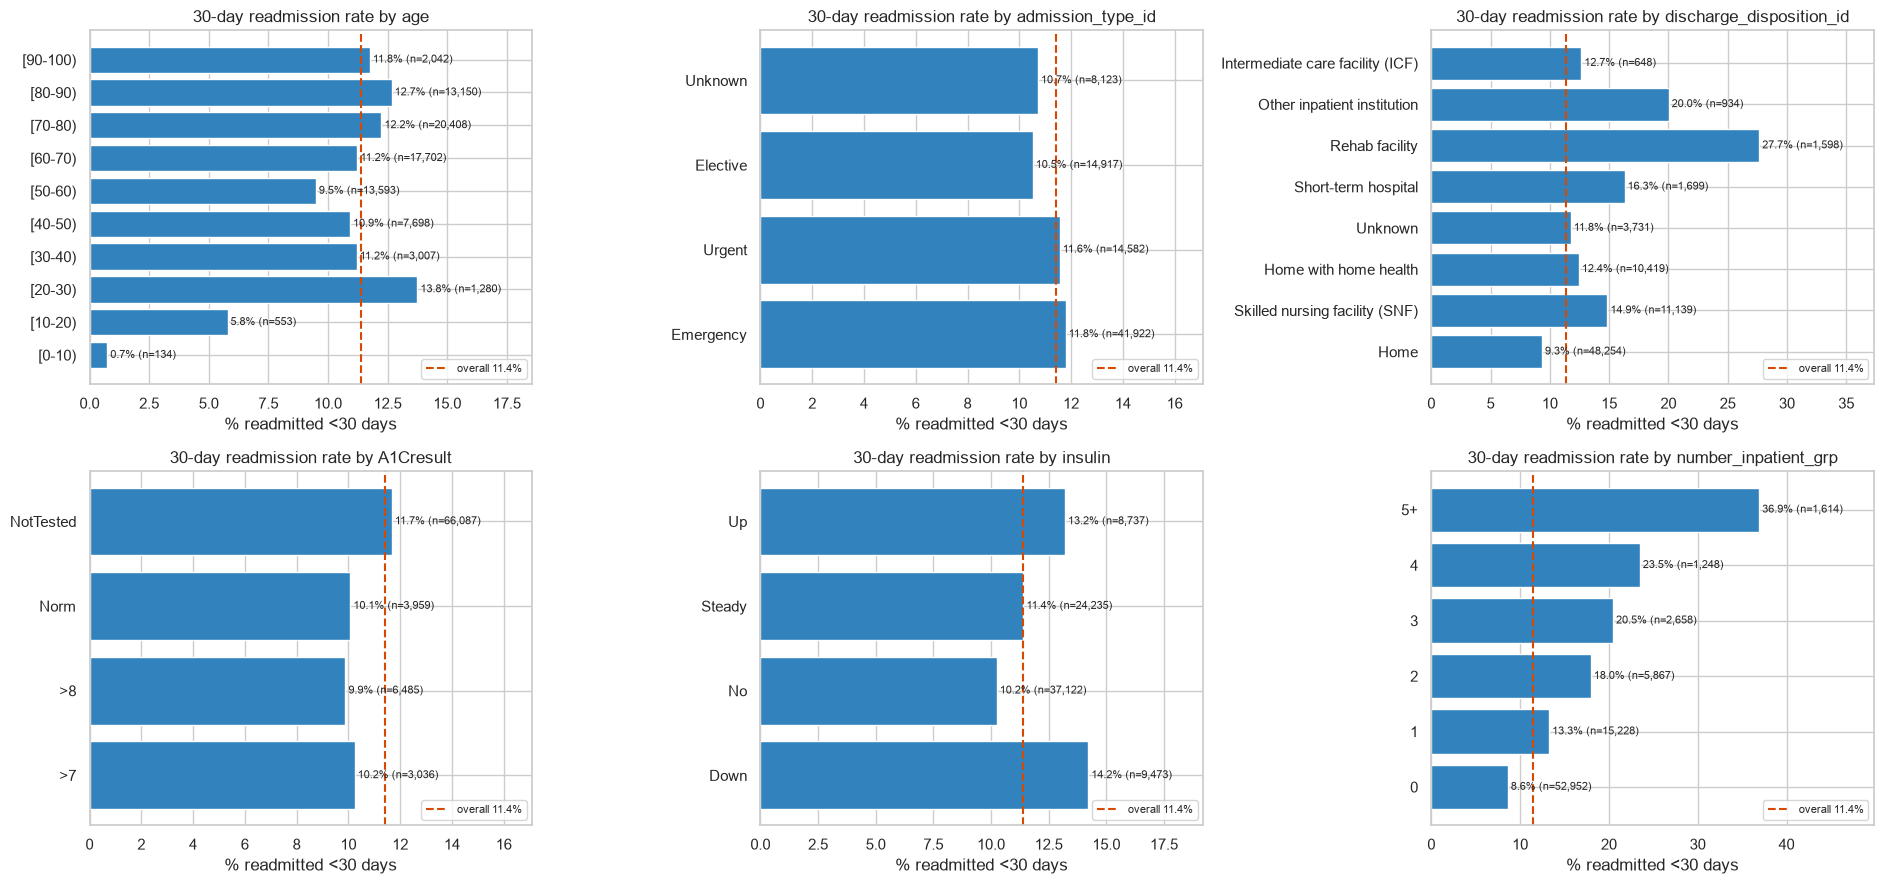

In [11]:
# Readmission rate by key categorical features

def short(s, n=38):
    return s if len(s) <= n else s[: n - 1] + "…"


def rate_table(frame, col, labels=None, min_n=50, top_n=None):
    g = frame.groupby(col, dropna=False)["target"].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    if top_n:
        g = g.sort_values("size", ascending=False).head(top_n)
    g["rate"] = g["mean"] * 100
    idx = [("Unknown" if pd.isna(i) else str(i)) for i in g.index]
    if labels is not None:
        idx = [short(labels.get(int(i), i)) if str(i).isdigit() else i for i in idx]
    g.index = idx
    return g

# Short display names for the long discharge descriptions
DISCHARGE_SHORT = {
    1: "Home",
    2: "Short-term hospital",
    3: "Skilled nursing facility (SNF)",
    4: "Intermediate care facility (ICF)",
    5: "Other inpatient institution",
    6: "Home with home health",
    22: "Rehab facility",
}
disch_labels = {
    k: DISCHARGE_SHORT.get(k, v) for k, v in id_maps["discharge_disposition_id"].items()
}

panels = {
    "age": dict(),
    "admission_type_id": dict(labels=id_maps["admission_type_id"]),
    "discharge_disposition_id": dict(labels=disch_labels, top_n=8),
    "A1Cresult": dict(),
    "insulin": dict(),
}
tmp = eda_df.copy()
tmp["number_inpatient_grp"] = tmp["number_inpatient"].clip(upper=5).astype(int).astype(str)
tmp.loc[tmp["number_inpatient"] >= 5, "number_inpatient_grp"] = "5+"
panels["number_inpatient_grp"] = dict()

base_rate = eda_df["target"].mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(19, 9))
for ax, (col, kw) in zip(axes.ravel(), panels.items()):
    src = tmp
    g = rate_table(src, col, **kw)
    if col in ("age", "number_inpatient_grp"):
        g = g.sort_index()
    ax.barh(g.index, g["rate"], color="#3182bd")
    ax.axvline(base_rate, color="#d94801", ls="--", label=f"overall {base_rate:.1f}%")
    for y, (r, n) in enumerate(zip(g["rate"], g["size"])):
        ax.text(r, y, f" {r:.1f}% (n={n:,})", va="center", fontsize=8)
    ax.set_title(f"30-day readmission rate by {col}")
    ax.set_xlabel("% readmitted <30 days")
    ax.set_xlim(0, max(g["rate"].max() * 1.35, base_rate * 1.5))
    ax.legend(loc="lower right", fontsize=8)
save_show(fig, "04_readmission_rate_by_category")

**Notes**
- **Prior inpatient visits** give the strongest gradient: 8.6% for patients with none, rising to 36.9%
  for five or more.
- **Discharge destination** matters: patients sent to a rehab facility (27.7%), another inpatient institution
  (20.0%) or a short-term hospital (16.3%) are readmitted far more often than those sent home (9.3%).
- **Age** rises gently with age; the youngest groups (<20) are small and rarely readmitted.
- **Insulin**: a dose change during the stay (`Up` 13.2%, `Down` 14.2%) is linked to higher risk than
  `No` insulin (10.2%). **A1C** testing alone shows only small differences, consistent with Strack et al.,
  who found its effect depends on the primary diagnosis.

## 6.5 Correlation heatmap of numeric features

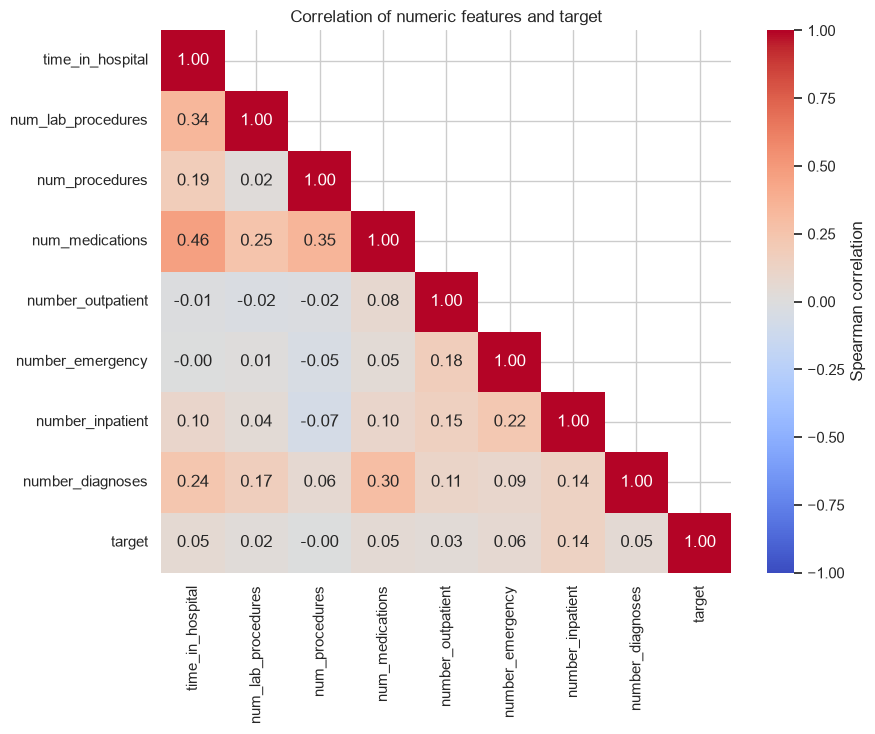

Correlation with target (Spearman):
number_inpatient      0.140
number_emergency      0.065
time_in_hospital      0.055
number_diagnoses      0.054
num_medications       0.047
number_outpatient     0.033
num_lab_procedures    0.025
num_procedures       -0.004
Name: target, dtype: float64

Pairs of numeric features with |corr| >= 0.4: [('time_in_hospital', 'num_medications', 0.46)]


In [12]:
# Correlation heatmap (numeric features + target)
# Spearman is used because the count features are heavily right-skewed.
corr_cols = NUMERIC_FEATURES + ["target"]
corr = eda_df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman correlation"})
ax.set_title("Correlation of numeric features and target")
save_show(fig, "05_numeric_correlation_heatmap")

print("Correlation with target (Spearman):")
print(corr["target"].drop("target").sort_values(ascending=False).round(3))

high = [(a, b, round(float(corr.loc[a, b]), 2))
        for i, a in enumerate(NUMERIC_FEATURES) for b in NUMERIC_FEATURES[i + 1:]
        if abs(corr.loc[a, b]) >= 0.4]
print("\nPairs of numeric features with |corr| >= 0.4:", high)

**Notes**
- No pair of numeric features is strongly correlated. The largest is `time_in_hospital` vs
  `num_medications` (rho = 0.46), so multicollinearity among numeric inputs is limited and no numeric
  feature needs to be removed for redundancy.
- Every individual correlation with the target is weak; the largest is `number_inpatient` (0.14).
  Readmission is not explained by any single variable, which is expected for this problem and is in line
  with the moderate ROC-AUC values (0.64-0.68) reported in the related work.

## 6.6 Association between categorical features (Cramér's V)

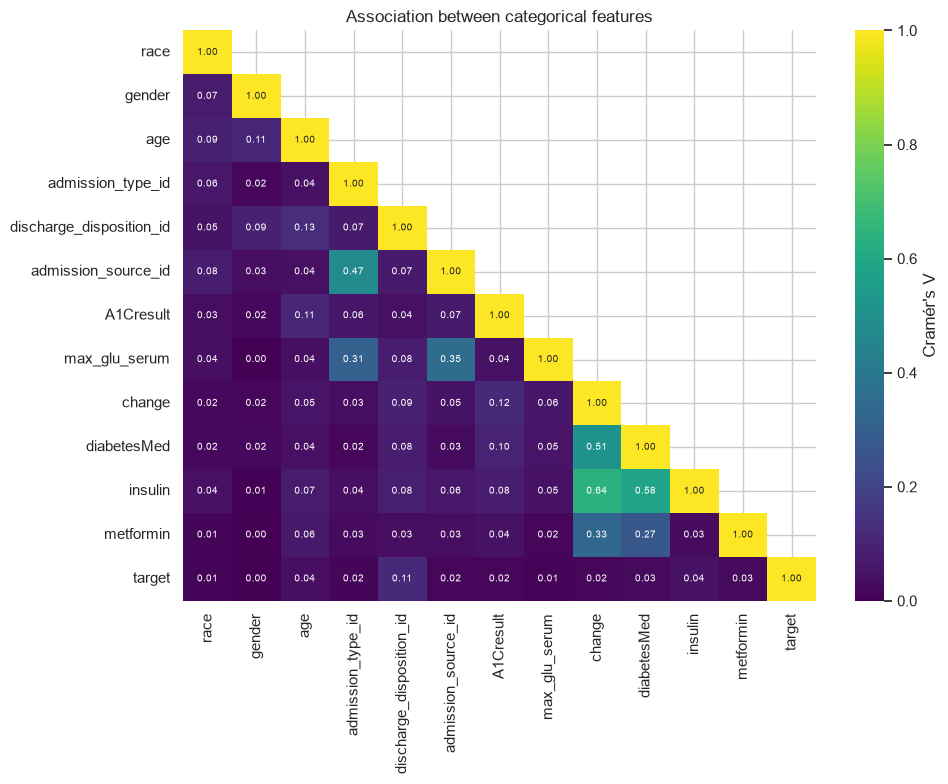

Cramér's V with target:
discharge_disposition_id    0.113
insulin                     0.043
age                         0.038
diabetesMed                 0.026
metformin                   0.025
A1Cresult                   0.019
admission_source_id         0.018
change                      0.017
admission_type_id           0.015
race                        0.013
max_glu_serum               0.011
gender                      0.000
Name: target, dtype: float64

Pairs of categorical features with V >= 0.4: [('admission_type_id', 'admission_source_id', 0.47), ('change', 'diabetesMed', 0.51), ('change', 'insulin', 0.64), ('diabetesMed', 'insulin', 0.58)]


In [13]:
# Association between categorical features (Cramér's V)
# Bias-corrected Cramér's V between two categorical series.
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    n = ct.values.sum()
    chi2 = chi2_contingency(ct, correction=False)[0]
    r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    denom = min(kc - 1, rc - 1)
    return np.sqrt(phi2 / denom) if denom > 0 else np.nan


CAT_FOR_V = [
    "race", "gender", "age", "admission_type_id", "discharge_disposition_id",
    "admission_source_id", "A1Cresult", "max_glu_serum", "change", "diabetesMed",
    "insulin", "metformin", "target",
]
cat_frame = eda_df[CAT_FOR_V].copy()
for c in CAT_FOR_V:
    cat_frame[c] = cat_frame[c].fillna("Unknown").astype(str)

V = pd.DataFrame(np.eye(len(CAT_FOR_V)), index=CAT_FOR_V, columns=CAT_FOR_V)
for i, a in enumerate(CAT_FOR_V):
    for b in CAT_FOR_V[i + 1:]:
        V.loc[a, b] = V.loc[b, a] = cramers_v(cat_frame[a], cat_frame[b])

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(V, dtype=bool), k=1)
sns.heatmap(V.astype(float), mask=mask, annot=True, fmt=".2f", cmap="viridis",
            vmin=0, vmax=1, ax=ax, annot_kws={"size": 7}, cbar_kws={"label": "Cramér's V"})
ax.set_title("Association between categorical features")
save_show(fig, "06_categorical_cramers_v")

print("Cramér's V with target:")
print(V["target"].drop("target").sort_values(ascending=False).round(3))

high_v = [(a, b, round(float(V.loc[a, b]), 2))
          for i, a in enumerate(CAT_FOR_V[:-1]) for b in CAT_FOR_V[i + 1:-1]
          if V.loc[a, b] >= 0.4]
print("\nPairs of categorical features with V >= 0.4:", high_v)

**Notes**
- Unlike the numeric features, some categorical features are strongly redundant. `change` and
  `diabetesMed` (V = 0.51) are summaries of the medication columns (a medication change implies diabetes
  medication), and `insulin` is strongly associated with both (V = 0.64 and 0.58). `admission_type_id` and
  `admission_source_id` are also associated (V = 0.47): emergency admissions mostly come through the
  emergency room.
- Among categorical features, `discharge_disposition_id` has the strongest association with the target
  (V = 0.11); all others are below 0.05.
- These redundancies are a reason to use a feature-selection step and to prefer regularised or tree-based
  models, which cope better with correlated inputs than an unregularised linear model.

## 6.7 Cardinality and repeated patients

In [14]:
# Cardinality and extra checks (feeds into the preprocessing plan)
print("Number of distinct values in categorical columns (high cardinality -> needs grouping):")
cat_cols_now = df.select_dtypes(exclude="number").columns
card = df[cat_cols_now].nunique().sort_values(ascending=False)
print(card.head(10))

print("\nTop 10 medical_specialty values (incl. missing):")
print(df["medical_specialty"].value_counts(dropna=False).head(10))

print("\nEncounters per patient (train+test cohort):")
epp = df.groupby("patient_nbr").size()
print(epp.describe().round(2))
print(f"Patients with >1 encounter: {(epp > 1).sum()} ({(epp > 1).mean() * 100:.1f}%)")

Number of distinct values in categorical columns (high cardinality -> needs grouping):
diag_3                      786
diag_2                      747
diag_1                      715
medical_specialty            72
discharge_disposition_id     19
payer_code                   17
admission_source_id          14
age                          10
race                          5
admission_type_id             5
dtype: int64

Top 10 medical_specialty values (incl. missing):
medical_specialty
NaN                           48614
InternalMedicine              14237
Emergency/Trauma               7419
Family/GeneralPractice         7252
Cardiology                     5278
Surgery-General                3059
Nephrology                     1539
Orthopedics                    1392
Orthopedics-Reconstructive     1230
Radiologist                    1121
Name: count, dtype: int64

Encounters per patient (train+test cohort):
count    69987.00
mean         1.42
std          1.09
min          1.00
25%      

**Notes**
- The ICD-9 diagnosis columns have over 700 distinct codes each, and `medical_specialty` has 72 levels.
  One-hot encoding them directly would create about 2,300 sparse columns, most seen only a handful of times,
  so they are grouped before encoding (Section 7).
- 23.3% of patients have more than one encounter (up to 40). Encounters of the same patient are not
  independent, which confirms the need for a patient-grouped split and grouped cross-validation later.

## 6.8 Key insights and challenges from the EDA

1. **Class imbalance.** Only 11.4% of encounters are positive. Accuracy is misleading (88.6% for a
   majority-class predictor), so we use PR-AUC and test class weighting and resampling.
2. **Weak individual signals.** The strongest single predictors are prior inpatient visits, discharge
   destination, and insulin changes, but no feature has a correlation above 0.14 with the target.
   Useful predictions will have to combine many weak signals.
3. **Skewed counts with many extreme values.** Prior-visit counts are heavily right-skewed. Their extreme
   values are genuine and informative, so they should be transformed, not removed.
4. **Informative missingness.** `medical_specialty` and `payer_code` are missing for 40-50% of encounters
   and missingness is related to the outcome for some columns, so "Missing" is kept as its own category.
5. **High-cardinality categories and redundancy.** Diagnosis codes need grouping, near-constant medication
   columns add little, and several categorical features are strongly associated with each other.
6. **Repeated patients.** 23.3% of patients have several encounters, so every split and every
   cross-validation fold must be grouped by patient to avoid leakage.